In [2]:
%pip install kagglehub


   ---------------- ----------------------- 2/5 [protobuf]
   ---------------- ----------------------- 2/5 [protobuf]
   ------------------------ --------------- 3/5 [kagglesdk]
   ------------------------ --------------- 3/5 [kagglesdk]
   ------------------------ --------------- 3/5 [kagglesdk]
   ---------------------------------------- 5/5 [kagglehub]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


## 데이터 불러오기

In [ ]:
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats

plt.rcParams["font.family"] = "Malgun Gothic"   # 맥이면 "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False       # 마이너스 기호 깨짐 방지


path = kagglehub.dataset_download("yufengsui/mobile-games-ab-testing")
print(os.listdir(path))   # 폴더 안 파일 확인 → cookie_cats.csv 가 보여야 함

df0 = pd.read_csv(os.path.join(path, "cookie_cats.csv"))
df = df0.copy()
df.head()


['cookie_cats.csv']


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 1. 데이터 점검

In [28]:
def title(text):
    print("\n" + "=" * 50)
    print(f"  {text}")
    print("=" * 50)

# 1) 기본 확인
title("1. 기본 확인")
print(f"행 수: {df.shape[0]:,} / 열 수: {df.shape[1]}")
print("\n[자료형]")
print(df.dtypes.to_string())
print("\n[결측치]")
print(df.isna().sum().to_string())

# 2) 중복 확인
title("2. 중복 확인")
print(f"중복 userid: {df['userid'].duplicated().sum()}건")

# 3) 배정 일관성
title("3. 배정 일관성")
print(df["version"].value_counts().to_string())

# 4) SRM 점검
title("4. SRM 점검")
n_a = (df["version"] == "gate_30").sum()
n_b = (df["version"] == "gate_40").sum()
chi2, p = stats.chisquare([n_a, n_b], [(n_a + n_b) / 2] * 2)
print(f"gate_30: {n_a:,}명 ({n_a/(n_a+n_b):.2%})")
print(f"gate_40: {n_b:,}명 ({n_b/(n_a+n_b):.2%})")
print(f"χ² = {chi2:.3f}, p = {p:.4f}")
print("→ 판정:", "정상" if p >= 0.05 else "SRM 의심 (데이터 유지, 한계에 기록)")

# 5) 이상치 확인
title("5. 이상치 확인 (sum_gamerounds)")
print(df["sum_gamerounds"].describe().round(1).to_string())

# 정제 전후
title("정제 전후 행 수")
df = df.drop_duplicates(subset="userid")
print(f"정제 전: {len(df0):,}행 → 정제 후: {len(df):,}행")


  1. 기본 확인
행 수: 90,189 / 열 수: 5

[자료형]
userid            int64
version             str
sum_gamerounds    int64
retention_1        bool
retention_7        bool

[결측치]
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0

  2. 중복 확인
중복 userid: 0건

  3. 배정 일관성
version
gate_40    45489
gate_30    44700

  4. SRM 점검
gate_30: 44,700명 (49.56%)
gate_40: 45,489명 (50.44%)
χ² = 6.902, p = 0.0086
→ 판정: SRM 의심 (데이터 유지, 한계에 기록)

  5. 이상치 확인 (sum_gamerounds)
count    90189.0
mean        51.9
std        195.1
min          0.0
25%          5.0
50%         16.0
75%         51.0
max      49854.0

  정제 전후 행 수
정제 전: 90,189행 → 정제 후: 90,189행


💡 SRM(Sample Ratio Mismatch) — 50:50으로 나눴다면 그룹 크기도 대략 반반이어야 합니다. 한쪽이 유독 많으면 배정 로직에 버그가 있다는 신호입니다.
여기서는 p가 커야 정상입니다(= 의도한 비율과 다르지 않다). 평소 검정과 해석 방향이 반대이니 주의하세요.

> SRM 점검: gate_30 44,700명(49.56%), gate_40 45,489명(50.44%), χ²(1) = 6.90, p = 0.0086. 50:50 배정 가정과 통계적으로 차이가 있어 SRM이 의심된다. 다만 불균형 크기는 0.44%p로 작고, 원인을 데이터로 확인할 수 없으며 의도한 배정 비율도 명시되어 있지 않다. 행을 임의로 제거하면 오히려 편향이 생길 수 있으므로 데이터는 그대로 유지하고, 이 점을 결론의 한계로 기록한다.

## 2. 질문과 가설

#### $\color{#1f77b4}{\textbf{■ 분석 질문}}$
첫 번째 관문을 레벨 30에서 레벨 40으로 미루면, 설치 7일 뒤에도 게임에 돌아오는 유저 비율이 달라질까?

#### $\color{#1f77b4}{\textbf{■ 주 지표}}$
`retention_7` (설치 7일 후 재접속 여부)  
게임 입장에서 하루 뒤 재접속보다 일주일 뒤에도 남아 있는지가 장기 유지에 더 중요하다고 판단해 주 지표로 정했다. `retention_1`과 `sum_gamerounds`는 보조 지표로 참고만 하고, 최종 의사결정은 $\color{#d62728}{\textbf{주 지표로만}}$ 내린다.

#### $\color{#1f77b4}{\textbf{■ 가설}}$
- $\color{#d62728}{H_0}$ (귀무가설): gate_30 그룹과 gate_40 그룹의 7일 리텐션 비율은 $\color{#d62728}{\text{같다}}$.
- $\color{#2ca02c}{H_1}$ (대립가설): gate_30 그룹과 gate_40 그룹의 7일 리텐션 비율은 $\color{#2ca02c}{\text{다르다}}$.

#### $\color{#1f77b4}{\textbf{■ 유의수준과 검정 방향}}$
- 유의수준: $\color{#d62728}{\alpha = 0.05}$
- 검정 방향: $\color{#d62728}{\textbf{양측 검정}}$

관문을 미루면 유저가 더 오래 즐길 수도 있지만, 반대로 쉬어 가는 타이밍이 늦어져 지루함을 느끼고 떠날 수도 있다. 어느 방향의 차이든 의사결정에 중요하므로 한쪽 방향만 보지 않는다.

## 3. 검정 선택

#### $\color{#1f77b4}{\textbf{■ 세 가지 질문}}$
1. 지표 유형: `retention_7`은 재접속 여부(True/False)이므로 **비율** 지표이다.
2. 집단 수: gate_30, gate_40 **2개** 집단이다.
3. 정규성·등분산: 연속형 지표가 아니므로 **해당하지 않는다.**

#### $\color{#1f77b4}{\textbf{■ 선택한 검정}}$
나는 $\color{#d62728}{\textbf{카이제곱 독립성 검정}}$을 골랐다. 주 지표 `retention_7`은 재접속 여부(비율)이고 비교 집단이 2개라, 데이터가 "버전 × 재접속 여부" 2×2 분할표로 정리되며 "두 그룹의 비율이 같다"는 가설은 곧 "버전과 재접속 여부가 독립이다"와 같기 때문이다.

#### $\color{#1f77b4}{\textbf{■ 가정 점검}}$
- 독립성: 한 유저는 한 그룹에만 속한다. (1단계에서 userid 중복 0건 확인)
- 기대빈도: 2×2 분할표의 모든 칸이 5 이상이다. (최소 기대빈도 8,317.1)

#### $\color{#1f77b4}{\textbf{■ 세부 설정}}$
연속성 보정(Yates)은 적용하지 않는다(`correction=False`). 표본이 충분히 커서 보정의 영향이 거의 없고, 보정하지 않으면 두 비율 z-검정과 같은 결과(χ² = z²)를 주어 신뢰구간 계산과 일관되게 해석할 수 있다.

> 카이제곱 검정의 가정은 정규성과 등분산성이 아니라 관측치가 서로 독립인지 그리고 모든 칸의 기대빈도 5 이상이여야한다.

In [29]:
from scipy.stats.contingency import expected_freq

table = pd.crosstab(df["version"], df["retention_7"])
expected = pd.DataFrame(expected_freq(table), index=table.index, columns=table.columns)

print("[기대빈도] 모든 칸이 5 이상이어야 함")
print(expected.round(1).to_string())
print(f"\n최소 기대빈도: {expected.values.min():,.1f}")

[기대빈도] 모든 칸이 5 이상이어야 함
retention_7    False   True 
version                     
gate_30      36382.9  8317.1
gate_40      37025.1  8463.9

최소 기대빈도: 8,317.1


## 4. 검정 수행

In [30]:
def title(text):
    print("\n" + "=" * 50)
    print(f"  {text}")
    print("=" * 50)

# 그룹별 인원과 재접속 수
n1 = (df["version"] == "gate_30").sum()
n2 = (df["version"] == "gate_40").sum()
x1 = df.loc[df["version"] == "gate_30", "retention_7"].sum()
x2 = df.loc[df["version"] == "gate_40", "retention_7"].sum()
p1, p2 = x1 / n1, x2 / n2

# ① 점추정
diff = p2 - p1          # 절대 차이
rel = p2 / p1 - 1       # 상대 차이

# ② 95% 신뢰구간 (두 비율 차이)
se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
z = stats.norm.ppf(0.975)
ci_low, ci_high = diff - z * se, diff + z * se

# 검정 + ③ 효과 크기
table = pd.crosstab(df["version"], df["retention_7"])
chi2, p, dof, _ = stats.chi2_contingency(table, correction=False)
cramers_v = np.sqrt(chi2 / table.values.sum())

# ===== 출력 =====
title("7일 리텐션 비율")
print(f"gate_30: {x1:,} / {n1:,}명 = {p1:.2%}")
print(f"gate_40: {x2:,} / {n2:,}명 = {p2:.2%}")

title("① 점추정 (gate_40 − gate_30)")
print(f"절대 차이: {diff*100:+.2f}%p")
print(f"상대 차이: {rel:+.2%}  (gate_30의 {p2/p1:.3f}배)")

title("② 95% 신뢰구간 (절대 차이)")
print(f"[{ci_low*100:+.2f}%p, {ci_high*100:+.2f}%p]")
print("→ 0을 포함:", "예 (차이가 없을 가능성 배제 못함)" if ci_low <= 0 <= ci_high else "아니오")

title("카이제곱 검정")
print(f"χ²({dof}) = {chi2:.2f}, p = {p:.4f}")
print("→ 판정:", "H0 기각 (유의함)" if p < 0.05 else "H0 기각 못함 (유의하지 않음)")

title("③ 효과 크기")
print(f"Cramér's V = {cramers_v:.4f}")


  7일 리텐션 비율
gate_30: 8,502 / 44,700명 = 19.02%
gate_40: 8,279 / 45,489명 = 18.20%

  ① 점추정 (gate_40 − gate_30)
절대 차이: -0.82%p
상대 차이: -4.31%  (gate_30의 0.957배)

  ② 95% 신뢰구간 (절대 차이)
[-1.33%p, -0.31%p]
→ 0을 포함: 아니오

  카이제곱 검정
χ²(1) = 10.01, p = 0.0016
→ 판정: H0 기각 (유의함)

  ③ 효과 크기
Cramér's V = 0.0105


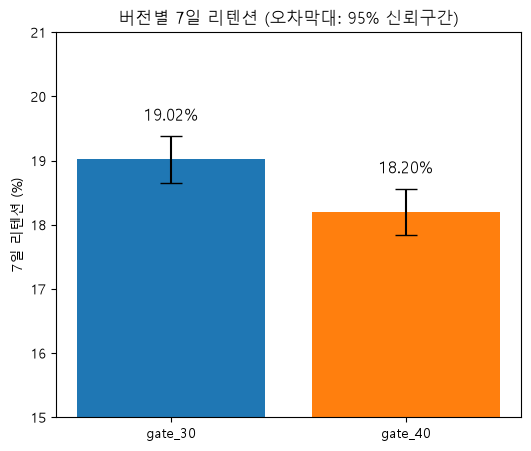

In [31]:
rates = [p1, p2]
errs = [1.96 * np.sqrt(p * (1 - p) / n) for p, n in zip(rates, [n1, n2])]

plt.figure(figsize=(6, 5))
plt.bar(["gate_30", "gate_40"], [r * 100 for r in rates],
        yerr=[e * 100 for e in errs], capsize=8, color=["#1f77b4", "#ff7f0e"])
for i, r in enumerate(rates):
    plt.text(i, r * 100 + 0.6, f"{r:.2%}", ha="center", fontsize=12)
plt.ylim(15, 21)
plt.ylabel("7일 리텐션 (%)")
plt.title("버전별 7일 리텐션 (오차막대: 95% 신뢰구간)")
plt.show()

> 각 그룹을 따로 본다.

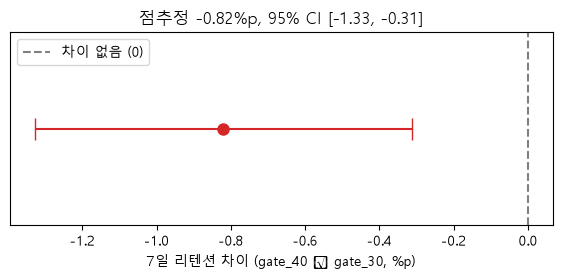

In [33]:
plt.rcParams.update({
    'font.family': 'Malgun Gothic',
    'axes.unicode_minus': False
})

plt.figure(figsize=(7, 2.5))
plt.errorbar(diff * 100, 0, xerr=[[(diff - ci_low) * 100], [(ci_high - diff) * 100]],
             fmt="o", color="#d62728", capsize=8, markersize=8)
plt.axvline(0, color="gray", linestyle="--", label="차이 없음 (0)")
plt.yticks([])
plt.xlabel("7일 리텐션 차이 (gate_40 − gate_30, %p)")
plt.title(f"점추정 {diff*100:+.2f}%p, 95% CI [{ci_low*100:+.2f}, {ci_high*100:+.2f}]")
plt.legend()
plt.show()

> 가운데 점 : gate_40 - gate_30 값
> 가로선: 그 차이의 흔들림 범위, 즉 신뢰구간
> 점선 왼쪽에 완전히 떨어져 있음 -> gate_40이 확실히 낮다(유의함)
> 점선 오른쪽에 완전히 떨어져 있음 -> gate_40이 확실히 높다(유의함)
> 점선을 가로지름 -> 차이가 없을 수도 있다(유의하지 않음)

> 두 그룹의 차이

## * 결과

#### $\color{#1f77b4}{\textbf{■ 보고 문장}}$
gate_40의 7일 리텐션이 더 낮았다(18.20% vs 19.02%).  
`−0.82%p (95% CI [−1.33, −0.31]), 상대 차이 −4.31%, χ²(1) = 10.01, p = .002, Cramér's V = 0.01`

#### $\color{#1f77b4}{\textbf{■ 3종 세트}}$
- ① 점추정: 절대 차이 $\color{#d62728}{-0.82\%p}$, 상대 차이 $\color{#d62728}{-4.31\%}$ (gate_30의 0.957배)
- ② 95% 신뢰구간: $[-1.33\%p, -0.31\%p]$ → 0을 포함하지 않음
- ③ 효과 크기: Cramér's V = 0.0105 (매우 작음)

#### $\color{#1f77b4}{\textbf{■ 해석}}$
p < 0.05이므로 $H_0$를 기각한다. 관문을 레벨 40으로 미루면 7일 리텐션이 낮아지며, 신뢰구간 전체가 음수이므로 감소 방향은 분명하다. 신뢰구간과 카이제곱 검정의 결론도 서로 일치한다. 다만 효과 크기는 매우 작아, 실질적인 영향은 절대 차이와 실제 유저 규모를 함께 고려해 판단해야 한다.

## 점추정
**점추정 = "우리 데이터로 계산한 딱 하나의 숫자"**예요.

비유: 국 간 보기

냄비 가득 끓인 국이 얼마나 짠지 알고 싶어요. 냄비를 다 마셔 볼 수는 없으니까 한 숟가락만 떠서 맛을 보죠. 그 한 숟가락이 "염도 1.2%"였다면, "이 냄비 국은 아마 염도 1.2% 정도일 거야"라고 말하겠죠.

여기서 1.2%가 점추정이에요. 일부(한 숟가락)를 보고 전체(냄비)에 대해 내놓은 가장 그럴듯한 숫자 하나인 거예요. 숫자 하나, 즉 "점" 하나로 추정했다고 해서 점추정이에요.

이 과제에서는

우리가 진짜 알고 싶은 건 **”앞으로 게임을 설치할 모든 유저"**에게 관문을 레벨 40으로 미루면 리텐션이 얼마나 달라지는가예요. 하지만 모든 유저를 볼 수는 없으니, 실험에 참여한 9만 명(한 숟가락)으로 계산하는 거죠.

예를 들어 실험 결과가 이렇다면,

gate_30: 19.0%가 돌아옴
gate_40: 18.2%가 돌아옴

→ 차이 = 18.2% − 19.0% = −0.8%p

이 −0.8%p가 점추정이에요. **"관문을 미루면 7일 리텐션이 약 0.8%p 떨어질 것 같다"는 우리의 최선의 추측이에요.**

## 카이제곱
> χ² 값과 p값은 "차이가 우연인가 아닌가"를 판정하는 숫자
> 두 번째 그래프에서, 신뢰구간 가로선이 0에서 떨어져 있으면 p < 0.05, 0을 가로지르면 p ≥ 0.05라서, 그래프만 봐도 카이제곱 검정의 결론과 같은 걸 알 수 있어요.

## 5. 한 걸음 더 - A. 이 실허믕ㄴ 효과를 잡을 '힘'이 있었나
1. +1%p 차이를 80% 확률로 잡으려면 그룹당 몇 명이 필요한가? (실험 설계 관점)
2. 지금 표본으로 잡을 수 있는 가장 작은 차이(MDE)는 얼마인가?

In [34]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

power_calc = NormalIndPower()
base = p1   # gate_30의 7일 리텐션 (기준)

# h(효과 크기)를 %p 차이로 바꾸는 함수
def h_to_p(h, base):
    return np.sin(np.arcsin(np.sqrt(base)) + h / 2) ** 2

# 1) +1%p를 80% 검정력으로 잡으려면 그룹당 몇 명?
h_1pp = proportion_effectsize(base + 0.01, base)
n_need = power_calc.solve_power(effect_size=h_1pp, power=0.8, alpha=0.05,
                                ratio=1, alternative="two-sided")

# 2) 지금 표본으로 잡을 수 있는 최소 효과(MDE)
h_mde = power_calc.solve_power(nobs1=n1, ratio=n2 / n1, power=0.8, alpha=0.05,
                               alternative="two-sided")
mde = h_to_p(h_mde, base) - base

title("5-A. 검정력과 MDE")
print(f"기준 리텐션 (gate_30): {base:.2%}")
print(f"\n[1] +1%p를 80% 검정력으로 잡는 데 필요한 인원: 그룹당 {np.ceil(n_need):,.0f}명")
print(f"    실제 인원: gate_30 {n1:,}명 / gate_40 {n2:,}명")
print(f"\n[2] 현재 표본의 MDE: ±{mde*100:.2f}%p")
print(f"    관측된 차이: {diff*100:+.2f}%p")
print("    → 관측 차이가 MDE보다", "크다" if abs(diff) > mde else "작다")


  5-A. 검정력과 MDE
기준 리텐션 (gate_30): 19.02%

[1] +1%p를 80% 검정력으로 잡는 데 필요한 인원: 그룹당 24,658명
    실제 인원: gate_30 44,700명 / gate_40 45,489명

[2] 현재 표본의 MDE: ±0.74%p
    관측된 차이: -0.82%p
    → 관측 차이가 MDE보다 크다


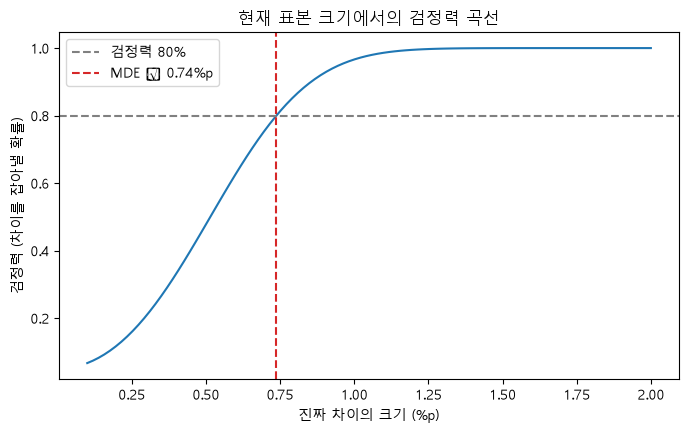

In [36]:
plt.rcParams.update({
    'font.family': 'Malgun Gothic',
    'axes.unicode_minus': False
})

diffs = np.linspace(0.001, 0.02, 100)
powers = [power_calc.power(proportion_effectsize(base + d, base), nobs1=n1,
                           ratio=n2 / n1, alpha=0.05) for d in diffs]

plt.figure(figsize=(8, 4.5))
plt.plot(diffs * 100, powers, color="#1f77b4")
plt.axhline(0.8, color="gray", linestyle="--", label="검정력 80%")
plt.axvline(mde * 100, color="#d62728", linestyle="--", label=f"MDE ≈ {mde*100:.2f}%p")
plt.xlabel("진짜 차이의 크기 (%p)")
plt.ylabel("검정력 (차이를 잡아낼 확률)")
plt.title("현재 표본 크기에서의 검정력 곡선")
plt.legend()
plt.show()

[1] 필요 인원: 실험 규모는 충분했다

+1%p 차이를 80% 확률로 잡으려면 그룹당 24,658명이 필요한데, 실제로는 그룹당 약 4만 5천 명이 있었어요. 필요한 인원의 약 1.8배예요. 즉 이 실험은 1%p 정도의 효과를 잡기에 넉넉한 규모였어요.

[2] MDE: 0.74%p 이상의 차이는 잡을 수 있었다

이 표본으로 80% 확률로 잡을 수 있는 가장 작은 차이는 약 0.74%p예요. 관측된 차이(0.82%p)가 이보다 커서, **”이 실험은 지금 발견한 크기의 차이를 잡아낼 힘이 있었다"**고 말할 수 있어요.

다만 0.82%p가 0.74%p를 아주 크게 넘는 건 아니라는 점도 같이 보면 좋아요. 그리고 4단계 신뢰구간의 끝이 −0.31%p였죠. 진짜 감소폭이 0.3~0.7%p 정도로 작았다면, 이 실험은 그걸 놓쳤을 가능성도 꽤 있었다는 뜻이에요. 이번엔 잡혔지만, “0.74%p보다 작은 효과는 이 실험 크기로는 확실히 구분하기 어렵다”는 게 이 실험의 한계예요.

## 6. 결론 및 의사결정

#### $\color{#1f77b4}{\textbf{① 질문과 가설}}$
- **질문**: 첫 번째 관문을 레벨 30에서 레벨 40으로 미루면, 설치 7일 뒤 돌아오는 유저 비율이 달라질까?
- **주 지표**: `retention_7`
- $H_0$: 두 버전의 7일 리텐션 비율은 같다. / $H_1$: 두 버전의 7일 리텐션 비율은 다르다.
- $\alpha = 0.05$, 양측 검정 (결과를 보기 전에 정했으며 끝까지 유지함)

#### $\color{#1f77b4}{\textbf{② 데이터 위생 점검}}$
- 결측치 0건, userid 중복 0건, version 값은 gate_30 / gate_40 두 가지뿐
- **정제 전 90,189행 → 정제 후 90,189행** (제거한 행 없음)
- SRM: gate_30 44,700명(49.56%) / gate_40 45,489명(50.44%), χ²(1) = 6.90, p = .009 → **SRM 의심.** 불균형 크기는 0.44%p로 작고, 원인을 확인할 수 없는 상태에서 행을 지우면 오히려 편향이 생기므로 데이터는 유지하고 한계에 기록함
- sum_gamerounds 최댓값 49,854의 극단값 존재 → 주 지표가 비율이라 영향이 거의 없어 유지함

#### $\color{#1f77b4}{\textbf{③ 검정 선택 근거}}$
주 지표가 재접속 여부(비율)이고 비교 집단이 2개이므로 **카이제곱 독립성 검정**을 사용했다. "두 버전의 비율이 같다"는 가설은 "버전과 재접속 여부가 독립이다"와 같은 뜻이다. 관측치 독립성(userid 중복 없음)과 기대빈도(모든 칸 5 이상) 가정을 확인했으며, 연속성 보정은 적용하지 않았다.

#### $\color{#1f77b4}{\textbf{④ 결과}}$
gate_40의 7일 리텐션이 더 낮았다(18.20% vs 19.02%).  
`−0.82%p (95% CI [−1.33, −0.31]), 상대 차이 −4.31%, χ²(1) = 10.01, p = .002, Cramér's V = 0.01`
- 신뢰구간 전체가 음수 → 감소 방향이 분명함
- 현재 표본의 MDE는 ±0.74%p로, 관측된 감소는 이 실험이 잡아낼 수 있는 크기였음

#### $\color{#1f77b4}{\textbf{⑤ 의사결정}}$
> $\color{#d62728}{\textbf{결정: 보류 — gate\_40을 출시하지 않고 기존 gate\_30을 유지한다.}}$

- 관문을 미루면 리텐션이 높아질 것이라는 기대와 달리, 7일 리텐션이 **유의하게 감소**했다.
- 감소폭은 작지만(100명 중 약 1명) 방향이 분명하고, 신뢰구간 어디에서도 개선 가능성이 보이지 않는다. 새 버전을 도입할 근거가 없다.
- 리텐션이 낮아지는 변경을 감수할 만한 다른 이점(예: 매출 증가)은 이 데이터로 확인할 수 없으므로, 현재로서는 기존 버전을 유지하는 것이 합리적이다.

#### $\color{#1f77b4}{\textbf{⑥ 한계}}$
- **SRM 의심**: 배정 비율이 50:50과 통계적으로 달랐다. 배정 과정에 문제가 있었다면 두 그룹이 완전히 비교 가능하지 않을 수 있다. 다만 의도한 배정 비율이 명시되어 있지 않고 불균형 크기도 작다.
- **효과 크기가 작음**: 실질적 영향은 유저 규모에 따라 달라지며, 이 감소가 비즈니스적으로 얼마나 중요한지는 판단하지 못했다.
- **MDE의 한계**: 0.74%p보다 작은 효과는 이 표본으로 안정적으로 검출하기 어렵다.
- **이 데이터로 알 수 없는 것**: 매출·결제 같은 수익 지표, 7일 이후의 장기 리텐션, 리텐션이 왜 떨어졌는지(메커니즘), 레벨 30·40 외의 다른 위치에서의 효과.
- **보조 지표 미검정**: `retention_1`, `sum_gamerounds`는 주 지표가 아니므로 의사결정에 사용하지 않았다.